# Wolf Sheep Predation: Comparing Two BehaviorSpace Experiments

Compare **100 sheep / 100 wolves** with **400 sheep / 400 wolves**, using the same revised model, reproduction probability grid, grass-regrowth settings, and 1500-tick time limit.

## Data links

The notebook loads the two course exports from GitHub. 

In [1]:
gitPlace='https://github.com/DACSS-Complexity/s5_sheep_wolves_experiment/raw/main/'

bs100link=gitPlace +'Wolf_Sheep_experiment_100_100-table.csv'
bs400link=gitPlace +'Wolf_Sheep_experiment_400_400-table.csv'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", None)

## 1. Load the data

Skip the six metadata lines and rename columns. 

In [3]:
def read_bs_table(path):
    df = pd.read_csv(path, skiprows=6)
    names = {
        "[run number]": "run_number",
        "sheep-reproduce-probability": "sheep_reproduce",
        "wolf-reproduce-probability": "wolf_reproduce",
        "grass-regrowth-time": "grass_regrowth_time",
        "[step]": "step",
        "land_with_grass": "land_with_grass",
        "count sheep": "count_sheep",
        "count wolves": "count_wolves",
    }
    missing = set(names) - set(df.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    df = df.rename(columns=names)[list(names.values())]
    df = df.apply(pd.to_numeric, errors="raise")
    if df.isna().any().any() or df.run_number.duplicated().any():
        raise ValueError("Expected complete data with one final row per run.")
    return df

exp_100 = read_bs_table(bs100link)
exp_400 = read_bs_table(bs400link)

Take a look:

In [4]:
exp_100.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1215 entries, 0 to 1214
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   run_number           1215 non-null   int64  
 1   sheep_reproduce      1215 non-null   int64  
 2   wolf_reproduce       1215 non-null   int64  
 3   grass_regrowth_time  1215 non-null   int64  
 4   step                 1215 non-null   int64  
 5   land_with_grass      1215 non-null   float64
 6   count_sheep          1215 non-null   int64  
 7   count_wolves         1215 non-null   int64  
dtypes: float64(1), int64(7)
memory usage: 76.1 KB


In [5]:
exp_400.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1215 entries, 0 to 1214
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   run_number           1215 non-null   int64  
 1   sheep_reproduce      1215 non-null   int64  
 2   wolf_reproduce       1215 non-null   int64  
 3   grass_regrowth_time  1215 non-null   int64  
 4   step                 1215 non-null   int64  
 5   land_with_grass      1215 non-null   float64
 6   count_sheep          1215 non-null   int64  
 7   count_wolves         1215 non-null   int64  
dtypes: float64(1), int64(7)
memory usage: 76.1 KB


## 2. Derived variables

- `sheep_survived` and `wolves_survived`: animals present at the endpoint.
- `total_collapse`: both animal populations extinct. Grass may remain.
- `grass_depleted`: grass availability is zero.
- `event`: either experiment stopping condition occurred.
- `censored`: tick 1500 was reached without an event.

An event at tick 1500 remains an observed event. Endpoint presence does not establish long-term persistence.

In [6]:
TIME_LIMIT = 1500

def add_derived(df, time_limit=TIME_LIMIT):
    df = df.copy()
    df["sheep_survived"] = df["count_sheep"] > 0
    df["wolves_survived"] = df["count_wolves"] > 0
    df["total_collapse"] = ~(df["sheep_survived"] | df["wolves_survived"])
    df["grass_depleted"] = df["land_with_grass"] == 0
    df["event"] = df["total_collapse"] | df["grass_depleted"]
    df["censored"] = (df["step"] == time_limit) & ~df["event"]
    if (df["step"] > time_limit).any() or (~df["event"] & ~df["censored"]).any():
        raise ValueError("An endpoint does not match the stopping rules or time limit.")
    return df

exp_100 = add_derived(exp_100)
exp_400 = add_derived(exp_400)
exp_100["config"] = "100Sheep_100Wolves"
exp_400["config"] = "400Sheep_400Wolves"
CONFIG_ORDER = ["100Sheep_100Wolves", "400Sheep_400Wolves"]
both = pd.concat([exp_100, exp_400], ignore_index=True)
both.head()

,run_number,sheep_reproduce,wolf_reproduce,grass_regrowth_time,step,land_with_grass,count_sheep,count_wolves,sheep_survived,wolves_survived,total_collapse,grass_depleted,event,censored,config
0,6,4,4,175,1500,80.891965,9,0,True,False,False,False,False,True,100Sheep_100Wolves
1,7,4,4,200,1500,88.504421,10,0,True,False,False,False,False,True,100Sheep_100Wolves
2,3,4,4,150,1500,56.055363,43,0,True,False,False,False,False,True,100Sheep_100Wolves
3,2,4,4,150,1500,46.559016,38,0,True,False,False,False,False,True,100Sheep_100Wolves
4,4,4,4,175,1500,48.289120,26,0,True,False,False,False,False,True,100Sheep_100Wolves


## 3. Descriptive summary

Compare animal extinction, endpoint animal presence, grass depletion, and time-limit censoring across the configurations.

In [7]:
summary_table = both.groupby("config")[[
    "total_collapse", "sheep_survived", "wolves_survived", "grass_depleted", "censored"
]].mean().reindex(CONFIG_ORDER)
summary_table

,total_collapse,sheep_survived,wolves_survived,grass_depleted,censored
config,,,,,
100Sheep_100Wolves,0.766255,0.233745,0.0,0.0,0.233745
400Sheep_400Wolves,0.950617,0.049383,0.0,0.0,0.049383


In [8]:
lines = ["**ANALYSIS 1:**"]
for label, sub in [("100/100", exp_100), ("400/400", exp_400)]:
    lines.append(
        f"**{label}:** both animal populations are extinct in {sub.total_collapse.mean():.1%} of runs. "
        f"Sheep remain in {sub.sheep_survived.mean():.1%} and wolves in {sub.wolves_survived.mean():.1%}."
    )
display(Markdown("\n\n".join(lines)))

**ANALYSIS 1:**

**100/100:** both animal populations are extinct in 76.6% of runs. Sheep remain in 23.4% and wolves in 0.0%.

**400/400:** both animal populations are extinct in 95.1% of runs. Sheep remain in 4.9% and wolves in 0.0%.

## 4. Heatmap: Animal extinction by reproduction probabilities

Each cell averages all repetitions and grass-regrowth settings for one sheep/wolf probability pair. In these exports, that is **15 runs**: three repetitions at each of five grass-regrowth times.

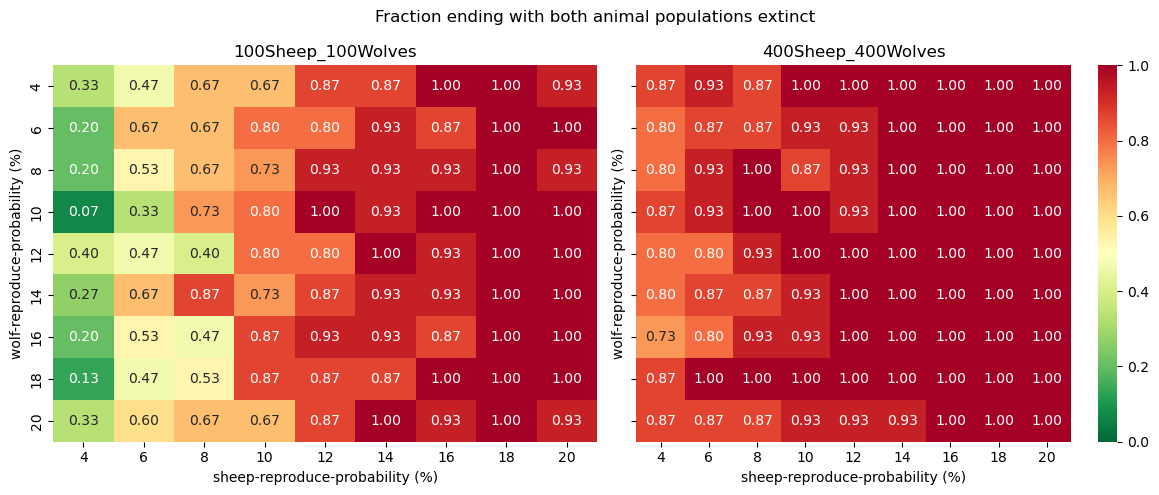

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (config_name, sub) in zip(axes, both.groupby("config")):
    pivot = sub.pivot_table(index="wolf_reproduce", columns="sheep_reproduce",
                             values="total_collapse", aggfunc="mean")
    sns.heatmap(pivot, ax=ax, cmap="RdYlGn_r", vmin=0, vmax=1,
                annot=True, fmt=".2f", cbar=(ax is axes[-1]))
    ax.set_title(config_name)
    ax.set_xlabel("sheep-reproduce-probability (%)")
    ax.set_ylabel("wolf-reproduce-probability (%)")

plt.suptitle("Fraction ending with both animal populations extinct")
plt.tight_layout()
plt.show()

**ANALYSIS 2:** In the **100/100** heatmap, colors generally shift from green toward red as you move from left to right. Animal extinction becomes more frequent as sheep reproduction increases, although the pattern is not perfectly consistent in every row.

Moving from top to bottom shows a less consistent pattern for wolf reproduction.

The **400/400** heatmap is mostly red, showing more frequent animal extinction across the grid.

## 5.- Kaplan-Meier survival curves and the log-rank test


### Installation

Install `lifelines` only if it is missing.

In [10]:
import importlib.util
if importlib.util.find_spec("lifelines") is None:
    get_ipython().run_line_magic("pip", "install -q lifelines")

In [11]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

Kaplan–Meier estimates the probability that neither experiment stopping condition has occurred by each tick. Runs reaching tick 1500 without an event are right-censored.

The event is both animal populations becoming extinct or grass availability reaching zero. In the supplied exports, all observed events are animal extinction. The curves pool the parameter grid.

The log-rank test compares the time-to-event distributions. It does not establish the ecological mechanism or validate the model against a real ecosystem.

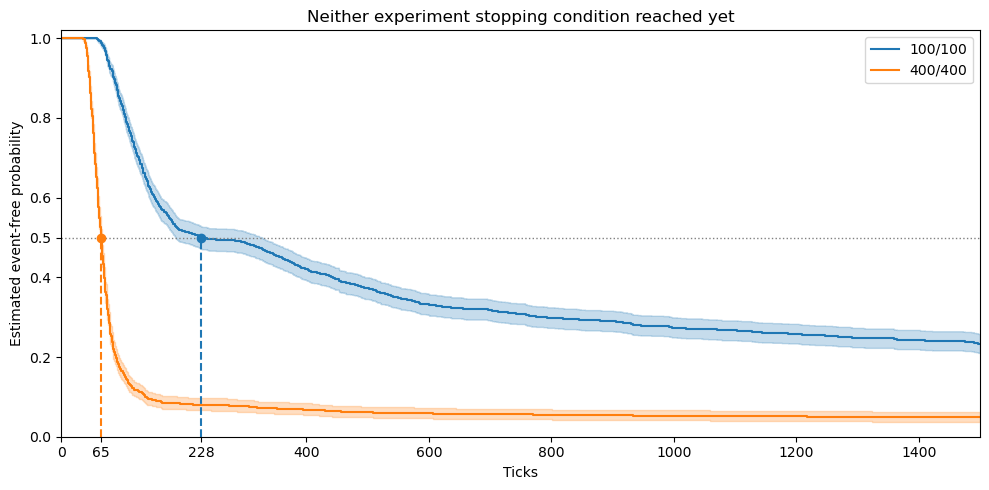

In [20]:
sub_100 = both[both["config"] == "100Sheep_100Wolves"]
sub_400 = both[both["config"] == "400Sheep_400Wolves"]

kmf_100 = KaplanMeierFitter()
kmf_400 = KaplanMeierFitter()

fig, ax = plt.subplots(figsize=(10, 5))

kmf_100.fit(
    sub_100["step"], event_observed=sub_100["event"], label="100/100"
)
kmf_100.plot_survival_function(ax=ax, color="tab:blue")

kmf_400.fit(
    sub_400["step"], event_observed=sub_400["event"], label="400/400"
)
kmf_400.plot_survival_function(ax=ax, color="tab:orange")

ax.axhline(0.5, color="gray", linestyle=":", linewidth=1)

medians = []
for kmf, color in [(kmf_100, "tab:blue"), (kmf_400, "tab:orange")]:
    median = kmf.median_survival_time_
    if np.isfinite(median):
        medians.append(median)
        ax.vlines(median, 0, 0.5, color=color, linestyle="--")
        ax.scatter(median, 0.5, color=color, zorder=5)

ax.set_title("Neither experiment stopping condition reached yet")
ax.set_xlabel("Ticks")
ax.set_ylabel("Estimated event-free probability")
ax.set_xlim(0, TIME_LIMIT)
ax.set_ylim(0, 1.02)

x_ticks = [
    t for t in ax.get_xticks()
    if 0 <= t <= TIME_LIMIT
    and all(abs(t - m) >= 50 for m in medians)
]
ax.set_xticks(sorted(set(x_ticks + medians)))
ax.set_yticks([0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0])

fig.tight_layout()
plt.show()

**ANALYSIS 3:** The **400/400** curve drops earlier and stays below the **100/100** curve. Runs therefore reach a stopping condition sooner in the 400/400 configuration.

The shaded bands show 95% confidence intervals.

In [13]:
results = logrank_test(sub_100["step"], sub_400["step"],
                       event_observed_A=sub_100["event"],
                       event_observed_B=sub_400["event"])
results.print_summary()

In [16]:
p_text = f"{results.p_value:.3g}" if results.p_value > 0 else "below numerical precision"

display(Markdown(
    f"**ANALYSIS 4:** The log-rank statistic is **{results.test_statistic:.2f}**, "
    f"with a p-value of **{p_text}**, providing strong evidence that survival times differ "
    "between configurations. The survival curves show the direction: "
    "**400/400 reaches animal extinction sooner than 100/100**. "
    f"The estimated median time is **{kmf_400.median_survival_time_:g} ticks for 400/400**, "
    f"compared with **{kmf_100.median_survival_time_:g} ticks for 100/100**."
))

**ANALYSIS 4:** The log-rank statistic is **1050.38**, with a p-value of **2.02e-230**, providing strong evidence that survival times differ between configurations. The survival curves show the direction: **400/400 reaches animal extinction sooner than 100/100**. The estimated median time is **65 ticks for 400/400**, compared with **228 ticks for 100/100**.